# Cubic gate $V=0.6X^3$: analysis

Characterises the cubic phase gate with coherent-state probes: a single scan of 21 probe
centres, reconstructed with $|n|\le2$ harmonics. Produces the cubic force and potential of
main-text Fig. 2(a,b), the coefficients $v_1,\dots,v_4$ of the main text and of SM *Cubic
gate*, and the cubic rows of the SM acquisition, acceptance and Sim tables.

**Input:** `cubic_0p6.zip` (raw single shots and the vacuum calibration) in the same folder as this notebook.
**Output:** tables, figures and `paper_values.json` in `results_cubic/`.

| § | content | used in |
|---|---|---|
| 0 | setup: imports and library functions | — |
| 1 | configuration and raw data | SM *Acquisition* |
| 2 | measurement: momentum scale, probe width, probe-averaged force, raw-shot bootstrap | SM *Measurement*, *Uncertainties* |
| 3 | compiled circuit: $K_g$ from the rotation angles run, and its exact channels | SM *Bosonic QSP construction* |
| 4 | pointwise force reconstruction, Sim, bandwidth test, Morse-rule cross-check | SM *Pointwise force reconstruction*, *Cubic gate: bandwidth* |
| 5 | band-limited target | SM *Reference curves* |
| 6 | analysis window and coefficients $v_n$ | main text; SM *Analysis windows*, *Cubic gate* |
| 7 | acceptance and post-selection | SM *Acceptance and post-selection* |
| 8 | agreement with Sim on the measured points | SM *Agreement with Sim* |
| 9 | values quoted in the paper | main text, SM |
| 10 | figure panels | main-text Fig. 2(a,b) |

**Conventions shared by the five analysis notebooks.** Fourier interval $|X|\le2$
(period $L=4$, $\gamma=\pi/2$); probe attenuation $H_n=e^{-\sigma_X^2k_n^2/2}$ with the
measured probe variance $\sigma_X^2$; noise-gain cap $1/H_n\le G=20$; uncertainties from
2000 raw-shot bootstrap replicas; functional-form fits (cubic, Morse) confined to the largest
window $|X|\le W$ over which a simulated perfect device (Sim plus the measured noise) is
consistent with the form (median $p\ge0.10$ at $W$ and at every smaller window); double-well
topology on $|X|\le1.5$.

Run top to bottom. Every number quoted in the paper is collected in `PAPER`, printed
between `===== PAPER VALUES` markers in section 9 and written to `paper_values.json` in the
output folder; `extract_outputs.py` gathers these blocks from all five notebooks.

## 0. Setup
Imports and library functions.

In [37]:
from pathlib import Path
import io, zipfile, re, json, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import chi2 as chi2_dist
from numpy.polynomial.hermite import hermgauss

def sha256_file(path):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        for block in iter(lambda:f.read(1024*1024),b""):
            h.update(block)
    return h.hexdigest()

def signed_label(name):
    m=re.search(r"alpha-([^_]+)_compressed",Path(name).name)
    if not m:
        raise ValueError(f"cannot parse probe label from {name}")
    s=m.group(1).lower()
    sign=-1.0 if s.startswith("m") else 1.0
    core=s[1:] if s.startswith("m") else s
    return sign*float(core)

def clock_seconds(name):
    m=re.match(r"(\d{2})-(\d{2})-(\d{2})_",Path(name).name)
    if not m:
        return np.nan
    h,mn,s=map(int,m.groups())
    return h*3600+mn*60+s

def jeffreys_binomial_se(k,n):
    k=np.asarray(k,float); n=np.asarray(n,float)
    a=k+0.5; b=n-k+0.5
    return np.sqrt(a*b/((a+b)**2*(a+b+1.0)))

# ---------------------------------------------------------------------
#  Crosshair calibration: probe width and momentum scale.
#
#  The tomography gate is ECD-3, so a vacuum crosshair is a Gaussian of width
#  w_vac = 1/3 in the swept DAC variable (supplement, "Probe width").
#  The crosshair is a characteristic-function cut of the undisplaced probe, so
#  a width-free fit measures the probe directly:
#
#      sigma_X^2 = (1/2) (w_vac / w)^2 ,
#
#  the quantity the Morse notebook reads off its probe cut.  The
#  same fit gives the readout contrast A, and with the DAC-to-phase-space scale
#  fixed by w_vac the momentum-conversion denominator is
#
#      den = sqrt(2) * A / w_vac .
#
#  A second fit with the width pinned at w_vac (a vacuum probe assumed) is kept
#  as the reference; its relative error is carried by den.  USE_MEASURED_WIDTH
#  in the configuration cell selects the measured width (the convention of
#  every gate) or the pinned reference (sigma_X^2 = 1/2).
# ---------------------------------------------------------------------
CROSSHAIR_W_FIXED = 1.0/3.0        # ECD-3 vacuum crosshair width, by construction
CROSSHAIR_ENFORCE_WIDTH = True     # keep the pinned-width reference fit; same in every gate notebook


def fit_crosshair_blob(blob, name, w_fixed=None, enforce=None):
    wf = CROSSHAIR_W_FIXED if w_fixed is None else float(w_fixed)
    en = CROSSHAIR_ENFORCE_WIDTH if enforce is None else bool(enforce)
    with np.load(io.BytesIO(blob)) as z:
        x  = np.asarray(z["xdata"], float)
        y0 = np.asarray(z["ydata_0"], float)
        y1 = np.asarray(z["ydata_1"], float) if "ydata_1" in z.files else None

    def g_fixed(x, b, A, x0):    return b + A*np.exp(-0.5*((x-x0)/wf)**2)
    def g_free(x, b, A, x0, w):  return b + A*np.exp(-0.5*((x-x0)/w)**2)

    def one(y):
        edge = np.r_[y[:4], y[-4:]]
        p0 = [float(edge.mean()), float(y.max()-edge.mean()), 0.0]

        # width free: the probe width and the readout contrast
        try:
            qopt, qcov = curve_fit(g_free, x, y, p0=p0+[wf], maxfev=30000)
            w_free = float(abs(qopt[3]))
            w_se   = float(np.sqrt(max(qcov[3, 3], 0.0))) if np.all(np.isfinite(qcov)) else np.nan
            s2   = 0.5*(wf/w_free)**2
            s2_se = (wf**2/w_free**3)*w_se if np.isfinite(w_se) else np.nan
            den_meas = float(qopt[1]*np.sqrt(2)/wf)
        except Exception:
            w_free = w_se = s2 = s2_se = den_meas = np.nan

        if en:
            popt, pcov = curve_fit(g_fixed, x, y, p0=p0, maxfev=30000)
            b, A, x0 = popt; w = wf
            grad = np.array([0.0, np.sqrt(2)/w, 0.0])
            gfun = g_fixed
        else:
            popt, pcov = curve_fit(g_free, x, y, p0=p0+[wf], maxfev=30000)
            b, A, x0, w = popt; w = abs(w)
            grad = np.array([0.0, np.sqrt(2)/w, 0.0, -A*np.sqrt(2)/(w*w)])
            gfun = g_free
        den = A*np.sqrt(2)/w
        var = float(grad@pcov@grad) if np.all(np.isfinite(pcov)) else 0.0
        se  = float(np.sqrt(max(var, 0.0)))

        # ---- momentum scale, applied here so that every force, every
        #      bootstrap draw and every table downstream is consistent -----
        #  contrast A from the width-free fit, DAC-to-phase-space scale from
        #  w_vac: den = sqrt(2) A_free / w_vac.  Its error keeps the relative
        #  error of the pinned-width fit.
        den_used, se_used = den, se
        if USE_MEASURED_WIDTH and np.isfinite(den_meas) and den_meas > 0:
            se_used = se*den_meas/den if den else se      # relative error preserved
            den_used = den_meas

        return {"den": float(den_used), "se": float(se_used),
                "den_pinned_width": float(den),
                "den_measured_width": float(den_meas),
                "measured_width_used": bool(USE_MEASURED_WIDTH),
                "params": popt, "cov": pcov, "g": gfun,
                "peak": float(b+A), "width": float(abs(w)),
                "width_free": w_free, "width_free_se": w_se,
                "sigma_X2": s2, "sigma_X2_se": s2_se,
                "den_measured_vs_pinned": float(den_meas/den) if den else np.nan,
                "calibration_mode": (("probe width measured: width-free fit, den = sqrt(2) A / w_vac"
                                  if USE_MEASURED_WIDTH else f"width pinned at {wf:.6f} (vacuum probe assumed)")
                                 if en else "width free, contrast and DAC scale both fitted (NOT the convention)")}

    p0_ = one(y0)
    p1_ = one(y1) if y1 is not None else None
    if np.isfinite(p0_["sigma_X2"]):
        SIGMA2_MEASURED.append(float(p0_["sigma_X2"]))   # primary channel only
    return {"name": name, "x": x, "y0": y0, "y1": y1,
            "primary": p0_, "secondary": p1_, "g": p0_["g"]}


def load_science_blob(blob, name):
    with np.load(io.BytesIO(blob)) as z:
        shot=np.asarray(z["single_shot"],float)
        pre=np.asarray(z["preselect"],float)
        x=np.asarray(z["y_displace"],float)
        saved_pg=float(z["num_in_g"]) if "num_in_g" in z.files else np.nan

        if shot.shape!=pre.shape or shot.ndim!=2:
            raise ValueError(f"{name}: invalid single_shot/preselect shape")

        accepted=(pre==0)
        n1=np.sum((shot==1)&accepted,axis=0).astype(int)
        n0=np.sum((shot==0)&accepted,axis=0).astype(int)
        nr=np.sum(~accepted,axis=0).astype(int)

        if "masked_0" in z.files:
            masked=np.asarray(z["masked_0"],float)
            expected=np.where(accepted,shot,np.nan)
            if not np.array_equal(np.isfinite(masked),np.isfinite(expected)):
                raise ValueError(f"{name}: masked_0 mask differs from preselect==0")
            finite=np.isfinite(masked)
            if finite.any() and np.max(np.abs(masked[finite]-expected[finite]))>0:
                raise ValueError(f"{name}: masked_0 values differ from accepted single_shot")

        pg=float(np.sum(n0+n1)/(shot.shape[0]*shot.shape[1]))
        if np.isfinite(saved_pg) and abs(pg-saved_pg)>1e-12:
            raise ValueError(f"{name}: raw p_g={pg} differs from stored num_in_g={saved_pg}")

    return {
        "name":name,"label":signed_label(name),
        "mu":0.2*signed_label(name),  # probe centres are labelled in steps of 0.2 in X
        "clock":clock_seconds(name),
        "x":x,"n0":n0,"n1":n1,"nr":nr,
        "N":shot.shape[0],"ncf":shot.shape[1],
        "pg":pg
    }

def cf_fit(rec, order):
    x=np.asarray(rec["x"],float)
    n0=np.asarray(rec["n0"],float); n1=np.asarray(rec["n1"],float)
    n=n0+n1
    y=n1/np.maximum(n,1)
    se=jeffreys_binomial_se(n1,n)
    scale=float(np.max(np.abs(x)))
    u=x/scale
    A=np.column_stack([u**j for j in range(order+1)])
    Aw=A/se[:,None]; yw=y/se
    beta,_,rank,sing=np.linalg.lstsq(Aw,yw,rcond=None)
    cov=np.linalg.pinv(Aw.T@Aw,rcond=1e-12)
    pred=A@beta
    resid=(y-pred)/se
    dof=max(len(y)-rank,1)
    return {
        "order":order,"slope":float(beta[1]/scale),
        "slope_se":float(np.sqrt(max(cov[1,1],0))/scale),
        "chi2":float(resid@resid),"dof":int(dof),
        "p":float(chi2_dist.sf(resid@resid,dof)),
        "condition":float(np.linalg.cond(Aw)),
        "coef":beta,"scale":scale,"pred":pred,"y":y,"se":se
    }

def bootstrap_raw(records, cal0, cal1, frac, B=2000, seed=20260824, order=5):
    rng=np.random.default_rng(seed)
    nr=len(records)
    Fb=np.empty((B,nr),float)
    Pgb=np.empty((B,nr),float)
    for b in range(B):
        d0=rng.normal(cal0["den"],cal0["se"])
        d1=rng.normal(cal1["den"],cal1["se"])
        for i,r in enumerate(records):
            n0b=np.empty(r["ncf"],int)
            n1b=np.empty(r["ncf"],int)
            for j,(a0,a1,ar) in enumerate(zip(r["n0"],r["n1"],r["nr"])):
                p=np.array([a0,a1,ar],float)/r["N"]
                draw=rng.multinomial(r["N"],p)
                n0b[j],n1b[j]=draw[0],draw[1]
            rr=dict(r)
            rr["n0"]=n0b; rr["n1"]=n1b
            fit=cf_fit(rr,order)
            den=(1-frac[i])*d0+frac[i]*d1
            Fb[b,i]=FORCE_SIGN*fit["slope"]/den
            Pgb[b,i]=float(np.sum(n0b+n1b)/(r["N"]*r["ncf"]))
    return Fb,Pgb

## 1. Configuration and raw data
Input archive, output folder and run settings; the raw single shots and the vacuum calibration are read here.

In [38]:
ZIP=Path("cubic_0p6.zip")
OUT=Path("results_cubic"); OUT.mkdir(exist_ok=True)
CF_ORDER=5
FORCE_SIGN=+1.0   # force = FORCE_SIGN * slope / den
N_BOOT=2000
BETA=np.pi/2


# ---------------- probe width: measured from the vacuum crosshair(s) -------
#  True   the probe variance sigma_X^2 = (1/2)(w_vac/w)^2 is read off the
#         width-free fit of the vacuum crosshair(s), and the momentum scale is
#         sqrt(2) A / w_vac with A from the same fit.  Carried through
#         everything downstream.  This is the convention of every gate.
#  False  reference only: width pinned at w_vac, sigma_X^2 = 1/2.
USE_MEASURED_WIDTH = True
SIGMA2_OVERRIDE    = None    # None: sigma_X^2 from the crosshair(s)
SIGMA2_MEASURED    = []      # filled by the crosshair fitter during the load

SIGMA2 = 0.5                 # provisional; §2.1 sets the value used downstream

if not ZIP.exists():
    raise FileNotFoundError("Place cubic_0p6.zip beside this notebook.")

with zipfile.ZipFile(ZIP) as z:
    names=z.namelist()
    qnames=[n for n in names if "QSP_imag_alpha" in n and n.endswith(".npz")]
    cnames=[n for n in names if "crosshair" in n.lower() and n.endswith(".npz")]
    records=[load_science_blob(z.read(n),n) for n in qnames]
    cross=[fit_crosshair_blob(z.read(n),n) for n in cnames]

records=sorted(records,key=lambda r:r["mu"])
if len(records)!=21:
    warnings.warn(f"Expected 21 probe positions; found {len(records)}.")
if len(cross)<1:
    raise FileNotFoundError("no crosshair in the archive")

# ---- calibration brackets ------------------------------------------------
#  One crosshair: used for every probe.  Two or more: the first and last in
#  acquisition time bracket the scan, and each probe's momentum scale is
#  interpolated between them by its acquisition time.
#  Times come from the HH-MM-SS_ prefix of the file names, modulo 24 h from the
#  first crosshair, so a scan may cross midnight.
def _bracket(cross, records):
    if len(cross) == 1:
        return cross[0], cross[0], np.zeros(len(records))
    tc = np.array([clock_seconds(c["name"]) for c in cross], float)
    ts = np.array([r["clock"] for r in records], float)
    if np.all(np.isfinite(tc)) and np.all(np.isfinite(ts)):
        best = None
        for i0 in range(len(cross)):
            rel_c = (tc - tc[i0]) % 86400
            rel_s = (ts - tc[i0]) % 86400
            i1 = int(np.argmax(rel_c))
            span = rel_c[i1]
            if span > 0 and np.all(rel_s <= span) and (best is None or span < best[2]):
                best = (i0, i1, span, rel_s)
        if best is None:
            raise ValueError("the crosshair times do not bracket the science files")
        i0, i1, span, rel_s = best
        return cross[i0], cross[i1], np.clip(rel_s / span, 0.0, 1.0)
    nm = [Path(c["name"]).name.lower() for c in cross]
    ib = [i for i, n in enumerate(nm) if "before" in n]
    ia = [i for i, n in enumerate(nm) if "after" in n]
    if len(ib) == 1 and len(ia) == 1:
        warnings.warn("no clock times in the file names: every probe takes the mean of "
                      "the before and after momentum scales")
        return cross[ib[0]], cross[ia[0]], np.full(len(records), 0.5)
    raise ValueError("cannot order the crosshairs: keep the HH-MM-SS_ prefix in their "
                     "file names, or name them *before* and *after*")

cross_before, cross_after, frac = _bracket(cross, records)
cal = cross_before["primary"]
cal_after = cross_after["primary"]
if len(cross) > 1:
    print(f"calibration brackets: {Path(cross_before['name']).name} -> "
          f"{Path(cross_after['name']).name};  momentum scale {cal['den']:.4f} -> "
          f"{cal_after['den']:.4f} ({100*(cal_after['den']/cal['den']-1):+.1f}%)")

print(f"crosshair width: enforced {cal['width']:.6f}, "
      f"free fit {cal['width_free']:.6f} +/- {cal['width_free_se']:.6f}")
print(f"crosshair width enforced: {CROSSHAIR_ENFORCE_WIDTH}, w = {CROSSHAIR_W_FIXED:.6f}")
print(f"USE_MEASURED_WIDTH = {USE_MEASURED_WIDTH};  provisional sigma_X^2 = {SIGMA2}"
      "  (section 2.1 sets the value used)")

audit=pd.DataFrame([{
    "archive":ZIP.name,
    "sha256":sha256_file(ZIP),
    "science_records":len(records),
    "unique_probe_centres":len(set(r["mu"] for r in records)),
    "repetitions_per_CF_point":records[0]["N"],
    "CF_points":records[0]["ncf"],
    "raw_binary_CF_measurements":sum(r["N"]*r["ncf"] for r in records),
    "crosshairs":len(cross),
    "primary_crosshair_channel":"ydata_0",
    "crosshair_denominator":cal["den"],
    "crosshair_denominator_se":cal["se"],
}])
display(audit)
audit.to_csv(OUT/"00_raw_audit.csv",index=False)

# ---------------- programmed target and windows, defined once ---------
C3_TARGET = 0.6                        # V = 0.6 X^3

def V_target(x):
    x = np.asarray(x, float)
    return C3_TARGET*x**3

def dV_target(x):
    x = np.asarray(x, float)
    return 3*C3_TARGET*x**2

W_ANALYSIS      = 2.0   # provisional; the analysis window is set in section 6
print(f"programmed target: V = {C3_TARGET}X^3,  V' = {3*C3_TARGET}X^2")
print(f"analysis window: set from Sim in section 6")

# ---------------- conventions shared by all five notebooks -------------
WINDOW_P_MIN = 0.10               # analysis-window rule: median p of Sim + measured noise >= this
GATE = "cubic"
PAPER = {}                      # every number quoted in the paper; printed in section 9

crosshair width: enforced 0.333333, free fit 0.318515 +/- 0.004328
crosshair width enforced: True, w = 0.333333
USE_MEASURED_WIDTH = True;  provisional sigma_X^2 = 0.5  (section 2.1 sets the value used)


,archive,sha256,science_records,unique_probe_centres,repetitions_per_CF_point,CF_points,raw_binary_CF_measurements,crosshairs,primary_crosshair_channel,crosshair_denominator,crosshair_denominator_se
0,cubic_0p6.zip,9d13305b2d276f4355e30751978a6de69dead05a71cd18...,21,21,10000,21,4410000,1,ydata_0,1.925152,0.024536


programmed target: V = 0.6X^3,  V' = 1.7999999999999998X^2
analysis window: set from Sim in section 6


### 1.1 Estimator setup
Fourier period, gain cap, grids, and the generalised-least-squares inverse used in section 4.

In [39]:
from scipy.integrate import cumulative_trapezoid

L = 2*np.pi/BETA                 # design period, = 4.0 for gamma = pi/2
MAX_INVERSE_GAIN = 20.0
A_FLOOR = 1e-4
XGRID = np.linspace(-2.0, 2.0, 1601)

def attenuation_table(sigma2, nmax=6, L=4.0):
    rows=[]
    for n in range(1, nmax+1):
        k = 2*np.pi*n/L
        H = np.exp(-0.5*sigma2*k*k)
        rows.append({"n":n, "k_n":k, "H_n":H, "inverse_gain":1.0/H})
    return pd.DataFrame(rows)

def choose_nmax(sigma2, max_inverse_gain=20.0, L=4.0, ncap=12):
    nmax=0
    for n in range(1, ncap+1):
        k = 2*np.pi*n/L
        if np.exp(0.5*sigma2*k*k) <= max_inverse_gain:
            nmax = n
        else:
            break
    if nmax < 1:
        raise ValueError("conditioning threshold rejects n=1")
    return nmax

def fourier_basis(x, nmax, L=4.0):
    """Unattenuated basis: evaluates the deconvolved function."""
    x = np.asarray(x, float)
    cols=[np.ones_like(x)]
    for n in range(1, nmax+1):
        k = 2*np.pi*n/L
        cols.extend([np.cos(k*x), np.sin(k*x)])
    return np.column_stack(cols)

def fourier_design(x, nmax, sigma2, L=4.0):
    """Attenuated basis: fitted coefficients are those of the deconvolved function,
    so the Gaussian transfer function is applied in the forward direction only."""
    x = np.asarray(x, float)
    cols=[np.ones_like(x)]
    for n in range(1, nmax+1):
        k = 2*np.pi*n/L
        H = np.exp(-0.5*sigma2*k*k)
        cols.extend([H*np.cos(k*x), H*np.sin(k*x)])
    return np.column_stack(cols)

def gls_fourier(x, y, cov, nmax, sigma2, L=4.0, rtol=1e-10):
    """GLS on the statistically resolved eigenmodes of the bootstrap covariance.
    The exact constraint A(mu=0)=1 appears as a null eigenmode and is dropped,
    rather than being given infinite weight or softened with a ridge parameter."""
    X = fourier_design(x, nmax, sigma2, L)
    y = np.asarray(y, float)
    C = np.asarray(cov, float); C = (C + C.T)/2
    ev, U = np.linalg.eigh(C)
    keep = ev > max(float(np.max(ev))*rtol, 1e-18)
    if not np.any(keep):
        raise ValueError("covariance has no resolved positive eigenmodes")
    Z = (U[:, keep]/np.sqrt(ev[keep])).T          # whitening operator
    Xw = Z@X; yw = Z@y
    coef,_,rank,_ = np.linalg.lstsq(Xw, yw, rcond=None)
    H = np.linalg.pinv(Xw, rcond=1e-12)@Z         # frozen resolution operator
    resid = Z@(y - X@coef)
    dof = max(int(keep.sum()-rank), 1)
    return {"coef":coef, "pred":X@coef, "H":H,
            "chi2":float(resid@resid), "dof":dof,
            "p":float(chi2_dist.sf(resid@resid, dof)),
            "rank":int(rank), "cov_rank":int(keep.sum()),
            "condition":float(np.linalg.cond(Xw))}

def normalized_channels(mu, force, pg, Fb, Pgb):
    """Divide both channels by the same measured p_g(0).  This cannot change q/a;
    it only removes a run-wise post-selection scale."""
    mu = np.asarray(mu, float)
    i0 = int(np.argmin(np.abs(mu)))
    if abs(float(mu[i0])) > 1e-9:
        raise ValueError("scan must contain the mu=0 normalisation probe")
    p0 = float(np.asarray(pg, float)[i0])
    Ab = Pgb/Pgb[:, [i0]]
    Qb = Pgb*Fb/Pgb[:, [i0]]
    return {"i0":i0,
            "A":np.asarray(pg,float)/p0,
            "Q":np.asarray(pg,float)*np.asarray(force,float)/p0,
            "Ab":Ab, "Qb":Qb,
            "covA":np.cov(Ab, rowvar=False, ddof=1),
            "covQ":np.cov(Qb, rowvar=False, ddof=1)}

def deconvolve_gls(ch, mu, xgrid, nmax, sigma2, L=4.0, a_floor=A_FLOOR):
    fa = gls_fourier(mu, ch["A"], ch["covA"], nmax, sigma2, L)
    fq = gls_fourier(mu, ch["Q"], ch["covQ"], nmax, sigma2, L)
    Bmat = fourier_basis(xgrid, nmax, L)
    a = Bmat@fa["coef"]; q = Bmat@fq["coef"]
    force = np.where(a > a_floor, q/a, np.nan)
    aB = (ch["Ab"]@fa["H"].T)@Bmat.T               # bootstrap through the same inverse
    qB = (ch["Qb"]@fq["H"].T)@Bmat.T
    fB = np.where(aB > a_floor, qB/aB, np.nan)
    return {"a":a, "q":q, "force":force,
            "a_boot":aB, "q_boot":qB, "force_boot":fB,
            "fit_a":fa, "fit_q":fq, "basis":Bmat,
            "min_a":float(np.nanmin(a)), "a_floor":a_floor}

def integrate_force(x, F, zero_at=0.0):
    x = np.asarray(x, float); F = np.asarray(F, float)
    if not np.all(np.isfinite(F)):
        raise ValueError("force has non-finite values; cannot integrate")
    V = cumulative_trapezoid(F, x, initial=0.0)
    return V - np.interp(zero_at, x, V)


NMAX = choose_nmax(SIGMA2, MAX_INVERSE_GAIN, L)
print(f"sigma_X^2 = {SIGMA2},  L = {L},  conditioning threshold = {MAX_INVERSE_GAIN}")
print(f"conditioning-selected nmax = {NMAX}")
display(attenuation_table(SIGMA2, 5, L))

sigma_X^2 = 0.5,  L = 4.0,  conditioning threshold = 20.0
conditioning-selected nmax = 2


,n,k_n,H_n,inverse_gain
0,1,1.570796,5.396415e-01,1.853082e+00
1,2,3.141593,8.480497e-02,1.179176e+01
2,3,4.712389,3.881039e-03,2.576630e+02
3,4,6.283185,5.172319e-05,1.933369e+04
4,5,7.853982,2.007397e-07,4.981576e+06


## 2. Measurement
### 2.1 Momentum scale and probe width
The vacuum crosshair is a characteristic-function cut of the undisplaced probe, so its fitted width $w$ is the probe width: $\sigma_X^2=\tfrac12(w_{\rm vac}/w)^2$ with $w_{\rm vac}=1/3$ the vacuum width the ECD-3 tomography is built for, as the Morse notebook reads $\sigma_X^2$ off its probe cut. The same fit gives the readout contrast $A$, and $\Lambda=\sqrt2A/w_{\rm vac}$. Where a scan has several crosshairs, $\sigma_X^2$ is their mean. Its uncertainty is not propagated.

In [40]:
# =====================================================================
#  §2.1 --- MOMENTUM-SCALE CALIBRATION.
#  The probe width and the readout contrast both come from the width-free
#  crosshair fit; sigma_X^2 is resolved at the end of this cell.
# =====================================================================
_rows=[]
for _k,_c in enumerate(cross):
    for _tag in ("primary","secondary"):
        _p=_c.get(_tag)
        if not _p: continue
        _rows.append({"crosshair":_c["name"],"channel":_tag,
                      "den":_p["den"],"se":_p["se"],
                      "width_pinned":_p["width"],"width_free":_p["width_free"],
                      "sigma_X2":_p["sigma_X2"],
                      "den_measured_vs_pinned":_p["den_measured_vs_pinned"]})
crosshair_audit=pd.DataFrame(_rows)
display(crosshair_audit)
crosshair_audit.to_csv(OUT/"22_crosshair_brackets.csv",index=False)
print(f"calibration mode: {cal['calibration_mode']}")
print(f"measured-width / pinned-width denominator = {cal['den_measured_vs_pinned']:.4f}")
print(f"denominator in use: {cal['den']:.6f} "
      f"({'measured width' if cal['measured_width_used'] else 'pinned width'})")
if len(crosshair_audit)>1:
    _d=crosshair_audit.den.to_numpy(float)
    print(f"readout-channel disagreement on the momentum scale: "
          f"{100*abs(_d[1]-_d[0])/_d[0]:.2f}%")


# ---------------------------------------------------------------------
#  RESOLVE THE PROBE WIDTH USED FROM HERE ON.
#  Every cell below reads SIGMA2 (and n_max derived from it), so this is the
#  only place it is set.  The momentum scale was set inside the crosshair
#  fitter, so the raw forces and the bootstrap that resamples them are
#  consistent with what is reported here.
# ---------------------------------------------------------------------
_s2_all = np.asarray([v for v in SIGMA2_MEASURED if np.isfinite(v)], float)
SIGMA2 = (float(SIGMA2_OVERRIDE) if SIGMA2_OVERRIDE is not None
          else (float(_s2_all.mean()) if _s2_all.size else 0.5))
if not USE_MEASURED_WIDTH:
    SIGMA2 = 0.5

print("\n=== probe width and momentum scale used from here on ===")
print(f"  USE_MEASURED_WIDTH = {USE_MEASURED_WIDTH}"
      + ("" if SIGMA2_OVERRIDE is None else f"   (sigma_X^2 overridden to {SIGMA2_OVERRIDE})"))
if _s2_all.size:
    print(f"  crosshair widths: {_s2_all.size}, sigma_X^2 = {_s2_all.mean():.4f}"
          + (f" +/- {_s2_all.std(ddof=1)/np.sqrt(_s2_all.size):.4f}" if _s2_all.size > 1 else ""))
print(f"  sigma_X^2  = {SIGMA2:.4f}")
if USE_MEASURED_WIDTH:
    print("  momentum scale: sqrt(2) A / w_vac with A from the width-free fit; "
          "every force below carries it.")
else:
    print("  momentum scale: pinned-width denominators (w = 1/3), sigma_X^2 = 1/2.")

NMAX = choose_nmax(SIGMA2, MAX_INVERSE_GAIN, L)
print(f"  n_max      = {NMAX}   (inverse gain "
      f"{np.exp(0.5*SIGMA2*(2*np.pi*NMAX/L)**2):.2f})")
display(attenuation_table(SIGMA2, 4, L))

,crosshair,channel,den,se,width_pinned,width_free,sigma_X2,den_measured_vs_pinned
0,cubic_0p6/crosshair_vacuum.npz,primary,1.925152,0.024536,0.333333,0.318515,0.547607,1.010200
1,cubic_0p6/crosshair_vacuum.npz,secondary,1.895653,0.021067,0.333333,0.327664,0.517453,1.003586


calibration mode: probe width measured: width-free fit, den = sqrt(2) A / w_vac
measured-width / pinned-width denominator = 1.0102
denominator in use: 1.925152 (measured width)
readout-channel disagreement on the momentum scale: 1.53%

=== probe width and momentum scale used from here on ===
  USE_MEASURED_WIDTH = True
  crosshair widths: 1, sigma_X^2 = 0.5476
  sigma_X^2  = 0.5476
  momentum scale: sqrt(2) A / w_vac with A from the width-free fit; every force below carries it.
  n_max      = 2   (inverse gain 14.91)


,n,k_n,H_n,inverse_gain
0,1,1.570796,0.508860,1.965177
1,2,3.141593,0.067049,14.914445
2,3,4.712389,0.002288,437.135407
3,4,6.283185,0.000020,49479.854854


### 2.2 Probe-averaged force and raw-shot bootstrap
Degree-5 polynomial fit to each 21-point characteristic-function cut; 2000 replicas resampling the raw shots and the calibration.

,label,mu,force,force_se_stat,pg,cf_p,force_se,pg_se
0,-10.0,-2.0,3.600365,0.061869,0.860105,0.251679,0.077561,0.000755
1,-9.0,-1.8,3.427168,0.061905,0.867900,0.531754,0.074157,0.000743
2,-8.0,-1.6,3.320730,0.062843,0.860776,0.903604,0.075526,0.000774
3,-7.0,-1.4,2.986770,0.063721,0.860252,0.494320,0.074742,0.000746
4,-6.0,-1.2,2.622847,0.064658,0.859390,0.072744,0.071963,0.000758
5,-5.0,-1.0,2.340626,0.065755,0.854686,0.744552,0.072680,0.000776
6,-4.0,-0.8,1.635980,0.066625,0.851343,0.651221,0.068867,0.000781
7,-3.0,-0.6,1.498255,0.067267,0.845881,0.095756,0.070604,0.000813
8,-2.0,-0.4,1.209414,0.067449,0.850033,0.559795,0.069861,0.000782
9,-1.0,-0.2,1.026671,0.067751,0.846443,0.355913,0.069876,0.000767


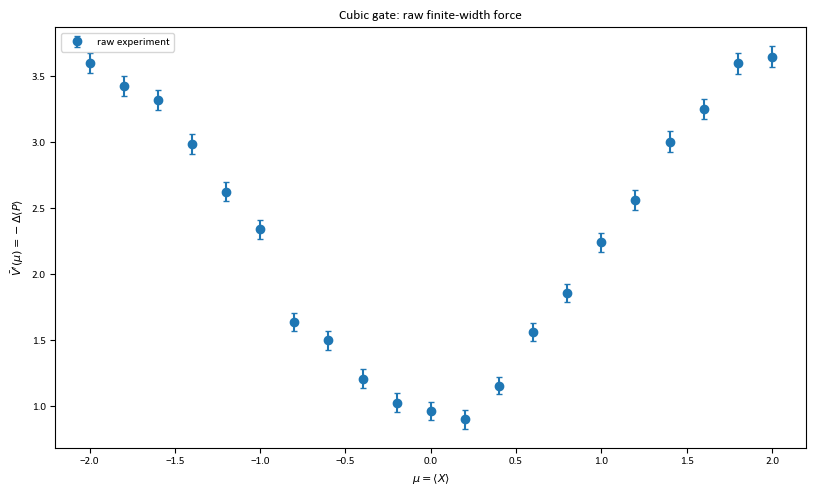

In [41]:
nominal=[]
for _i,r in enumerate(records):
    f=cf_fit(r,CF_ORDER)
    _den=(1-frac[_i])*cal["den"]+frac[_i]*cal_after["den"]   # bracketing calibrations
    F=FORCE_SIGN*f["slope"]/_den
    nominal.append({
        "label":r["label"],"mu":r["mu"],"force":F,
        "force_se_stat":f["slope_se"]/_den,
        "pg":r["pg"],"cf_p":f["p"]
    })
data=pd.DataFrame(nominal).sort_values("mu").reset_index(drop=True)

Fb,Pgb=bootstrap_raw(records,cal,cal_after,frac,B=N_BOOT,seed=20260824,order=CF_ORDER)
covF=np.cov(Fb,rowvar=False,ddof=1)
covPg=np.cov(Pgb,rowvar=False,ddof=1)
data["force_se"]=np.sqrt(np.clip(np.diag(covF),0,np.inf))
data["pg_se"]=np.sqrt(np.clip(np.diag(covPg),0,np.inf))
display(data)
data.to_csv(OUT/"04_raw_force_acceptance.csv",index=False)

plt.figure(figsize=(8.2,5.0))
plt.errorbar(data.mu,data.force,yerr=data.force_se,fmt="o",capsize=2,label="raw experiment")
plt.xlabel(r"$\mu=\langle X\rangle$")
plt.ylabel(r"$\bar V'(\mu)=-\Delta\langle P\rangle$")
plt.title("Cubic gate: raw finite-width force")
plt.legend(); plt.tight_layout()
plt.savefig(OUT/"05_raw_force.png",dpi=300); plt.show()

## 3. Compiled circuit
Built from the rotation angles that were run. $w=|K_g|^2$ and $q=-\mathrm{Im}[K_g^*K_g']$ are exact Fourier series of degree $M$, so the probe average of each is exact.

In [42]:
# =====================================================================
#  §3 --- THE COMPILED CIRCUIT.
#  Supplement, "Post-selected Kraus operator".
#
#  a(X) = |K_g|^2 and q(X) = -Im[K_g* K_g'] are EXACT finite Fourier series of
#  order M on the design period L, because K_g carries harmonics e^{i m gamma X}
#  with |m| <= M/2 of a single parity and both channels are quadratic in K_g.
#  Their coefficients come off by FFT to machine precision, and the
#  coherent-probe average is the closed form e^{-sigma^2 k^2/2} per harmonic.
# =====================================================================
# Cubic rotation angles actually run: 12 rotations, M = 11.
ROTS = [
    (0.184405, 2.93141, 2.9065),
    (1.39646,  3.8613,  0.0),
    (1.44834,  6.09264, 0.0),
    (1.47146,  0.411717,0.0),
    (1.11854,  5.85123, 0.0),
    (0.322625, 0.459188,0.0),
    (1.33891,  2.42186, 0.0),
    (0.734034, 3.06676, 0.0),
    (1.24941,  0.119462,0.0),
    (1.14211,  3.21129, 0.0),
    (0.688893, 0.101973,0.0),
    (0.794593, 3.12217, 0.0),
]

QSP_ORDER_M = len(ROTS) - 1
BETA = 2*np.pi/L                      # gamma = pi/2 for L = 4
assert abs(L - 4.0) < 1e-12, "design period is not 4; check the configuration"


def R_general(theta, phi, lam):
    return np.array([[np.exp(1j*(lam+phi))*np.cos(theta), np.exp(1j*phi)*np.sin(theta)],
                     [np.exp(1j*lam)*np.sin(theta),      -np.cos(theta)]], complex)


_RL = [R_general(*r) for r in ROTS]


def K_Kp(x):
    """Compiled accepted branch K_g(x) and its exact derivative."""
    S_  = np.array([[0, np.exp(1j*BETA*x/2)],
                    [np.exp(-1j*BETA*x/2), 0]], complex)
    Sp_ = np.array([[0, 1j*BETA/2*np.exp(1j*BETA*x/2)],
                    [-1j*BETA/2*np.exp(-1j*BETA*x/2), 0]], complex)
    U  = _RL[0].copy(); Up = np.zeros((2, 2), complex)
    for j in range(1, len(_RL)):
        Up = _RL[j] @ (Sp_ @ U + S_ @ Up)
        U  = _RL[j] @ S_ @ U
    return U[0, 0], Up[0, 0]


def _channel_coeffs(nfft=512):
    xq = np.arange(nfft)/nfft*L
    v  = [K_Kp(float(t)) for t in xq]
    K  = np.array([z[0] for z in v]); Kp = np.array([z[1] for z in v])
    return np.fft.fft(np.abs(K)**2)/nfft, np.fft.fft(-np.imag(np.conj(K)*Kp))/nfft


CA, CQ = _channel_coeffs()
_tail = max(max(abs(CA[n]) for n in range(QSP_ORDER_M+1, QSP_ORDER_M+20)),
            max(abs(CQ[n]) for n in range(QSP_ORDER_M+1, QSP_ORDER_M+20)))
print(f"compiled channels are exact Fourier series of order M = {QSP_ORDER_M}: "
      f"largest coefficient above M = {_tail:.2e}")


def series(c, x, sigma2=0.0, M=None):
    """sum_{|n|<=M} c_n e^{i k_n x}, Gaussian-smoothed when sigma2 > 0.  Exact."""
    m = QSP_ORDER_M if M is None else int(M)
    x = np.asarray(x, float)
    out = np.full(np.shape(x), c[0].real, float)
    for n in range(1, m+1):
        k = 2*np.pi*n/L
        out = out + 2*np.exp(-0.5*sigma2*k*k)*(c[n].real*np.cos(k*x) - c[n].imag*np.sin(k*x))
    return out


def compiled_coherent(mu, sigma2=None):
    """Coherent-probe response -> (F_g, p_g)."""
    s2 = SIGMA2 if sigma2 is None else float(sigma2)
    pg = series(CA, mu, s2)
    return series(CQ, mu, s2)/pg, pg


_v  = [K_Kp(float(t)) for t in XGRID]
_K  = np.array([w[0] for w in _v]); _Kp = np.array([w[1] for w in _v])
XCOMP       = np.asarray(XGRID, float).copy()
AMPL_COMP   = np.abs(_K)
VPHASE_COMP = -np.unwrap(np.angle(_K))
VPHASE_COMP = VPHASE_COMP - np.interp(0.0, XGRID, VPHASE_COMP)
FPOINT_COMP = series(CQ, XGRID)/series(CA, XGRID)

_direct = -np.imag(np.conj(_K)*_Kp)/np.maximum(AMPL_COMP**2, 1e-12)
print(f"pointwise q/a, series vs direct matrix product: "
      f"max |diff| = {np.max(np.abs(FPOINT_COMP-_direct)):.2e}")

print(f"\ncompiled cubic gate: {len(ROTS)} rotations, M = {QSP_ORDER_M}")

compiled channels are exact Fourier series of order M = 11: largest coefficient above M = 1.61e-16
pointwise q/a, series vs direct matrix product: max |diff| = 5.33e-15

compiled cubic gate: 12 rotations, M = 11


## 4. Pointwise force reconstruction
### 4.1 Deconvolution and Sim
Acceptance and force channels normalised by $p_g(\mu=0)$, deconvolved separately by GLS on the resolved modes of the bootstrap covariance, $|n|\le n_{\max}$. Sim is the compiled circuit put through the same frozen inverse.

In [43]:
# Reconstruction input: every probe centre, |mu| <= L/2.  The compiled gate is
# periodic with period L, so mu = -L/2 and +L/2 are two measurements of the same
# point of the series; both are fitted.
REC_SEL = np.abs(data.mu.to_numpy(float)) <= L/2 + 1e-9
mu = data.mu.to_numpy(float)[REC_SEL]
ch = normalized_channels(mu, data.force.to_numpy(float)[REC_SEL], data.pg.to_numpy(float)[REC_SEL],
                         Fb[:, REC_SEL], Pgb[:, REC_SEL])
rec = deconvolve_gls(ch, mu, XGRID, NMAX, SIGMA2, L)
print(f"reconstruction input: {int(REC_SEL.sum())} of {len(REC_SEL)} probe centres (|mu| <= {L/2:g})")
PAPER["recon.input_probe_centres"] = int(REC_SEL.sum())

measured_support = (XGRID >= data.mu.min()) & (XGRID <= data.mu.max())

gof = pd.DataFrame([
    {"channel":"normalised p_g  (A)", "chi2":rec["fit_a"]["chi2"], "dof":rec["fit_a"]["dof"],
     "p":rec["fit_a"]["p"], "resolved_cov_modes":rec["fit_a"]["cov_rank"],
     "condition":rec["fit_a"]["condition"]},
    {"channel":"normalised p_g F (Q)", "chi2":rec["fit_q"]["chi2"], "dof":rec["fit_q"]["dof"],
     "p":rec["fit_q"]["p"], "resolved_cov_modes":rec["fit_q"]["cov_rank"],
     "condition":rec["fit_q"]["condition"]},
])
display(gof)
gof.to_csv(OUT/"10_deconvolution_gof.csv", index=False)

print(f"min reconstructed a(X) on measured support = {rec['a'][measured_support].min():.4f}")


# ---- Sim: the compiled circuit, probe-averaged at the same centres,
#      normalised as the data and put through the same frozen inverse -------
PG_COMP_MU = series(CA, mu, SIGMA2)
Q_COMP_MU  = series(CQ, mu, SIGMA2)
A_COMP_N = PG_COMP_MU/PG_COMP_MU[ch["i0"]]
Q_COMP_N = Q_COMP_MU/PG_COMP_MU[ch["i0"]]
_ac = rec["basis"] @ (rec["fit_a"]["H"] @ A_COMP_N)
_qc = rec["basis"] @ (rec["fit_q"]["H"] @ Q_COMP_N)
F_COMP_EST = np.where(_ac > rec["a_floor"], _qc/_ac, np.nan)


def integrate_masked(F_all, mask=None, zero_at=0.0, x_all=None):
    """Integrate a force curve that may carry NaN (where the reconstructed
    acceptance falls below a_floor) over its finite points only."""
    x = XGRID if x_all is None else np.asarray(x_all, float)
    F = np.asarray(F_all, float)
    ok = np.isfinite(F) if mask is None else (np.asarray(mask, bool) & np.isfinite(F))
    out = np.full(x.shape, np.nan, float)
    if int(ok.sum()) >= 2:
        out[ok] = integrate_force(x[ok], F[ok], zero_at=zero_at)
    return out

reconstruction input: 21 of 21 probe centres (|mu| <= 2)


,channel,chi2,dof,p,resolved_cov_modes,condition
0,normalised p_g (A),600.214689,15,3.196529e-118,20,7.984024
1,normalised p_g F (Q),21.046424,16,1.767330e-01,21,12.446593


min reconstructed a(X) on measured support = 0.8846


### 4.2 Bandwidth
$n_{\max}=1,2,3$ on the same data (SM *Cubic gate: bandwidth*).

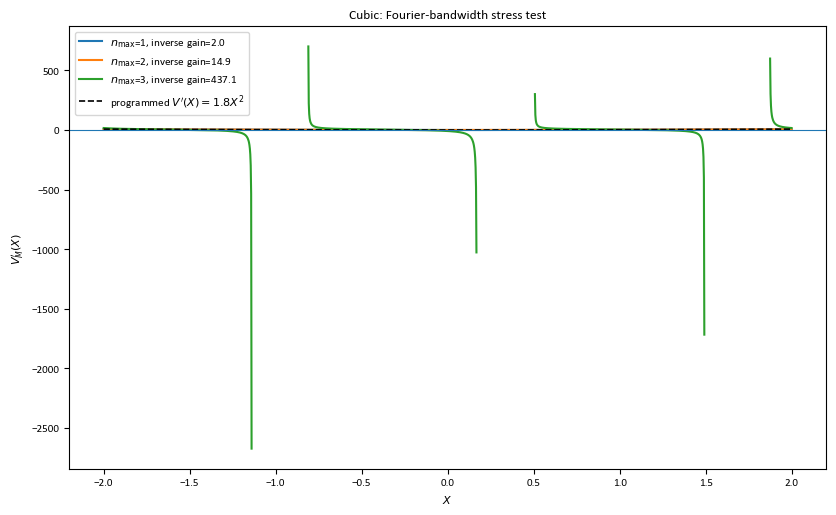

,nmax,inverse_gain,min_a,A_chi2,A_dof,A_p,Q_chi2,Q_dof,Q_p,F_point_at_0,F_point_at_1p5,rms_vs_target_1p5
0,1,1.965177,0.997363,1257.064136,17,7.541503e-257,22.435269,18,0.213232,-0.371062,4.060381,0.307793
1,2,14.914445,0.884617,600.214689,15,3.196529e-118,21.046424,16,0.176733,-0.177664,4.108544,0.191896
2,3,437.135407,-0.569244,459.321229,13,6.264682e-90,19.411410,14,0.149817,-8.727489,NaN,NaN


In [44]:
stress_rows=[]
plt.figure(figsize=(8.4,5.2))
for nm in (1,2,3):
    rr = deconvolve_gls(ch, mu, XGRID, nm, SIGMA2, L)
    gain = float(np.exp(0.5*SIGMA2*(2*np.pi*nm/L)**2))
    win = np.abs(XGRID) <= 1.5
    stress_rows.append({
        "nmax":nm, "inverse_gain":gain, "min_a":rr["min_a"],
        "A_chi2":rr["fit_a"]["chi2"], "A_dof":rr["fit_a"]["dof"], "A_p":rr["fit_a"]["p"],
        "Q_chi2":rr["fit_q"]["chi2"], "Q_dof":rr["fit_q"]["dof"], "Q_p":rr["fit_q"]["p"],
        "F_point_at_0":float(np.interp(0.0, XGRID, rr["force"])),
        "F_point_at_1p5":float(np.interp(1.5, XGRID, rr["force"])),
        "rms_vs_target_1p5":float(np.sqrt(np.mean((rr["force"][win]-1.8*XGRID[win]**2)**2))),
    })
    plt.plot(XGRID, rr["force"], label=f"$n_{{\\max}}$={nm}, inverse gain={gain:.1f}")
    del rr
plt.plot(XGRID, 1.8*XGRID**2, "k--", lw=1.2, label=r"programmed $V'(X)=1.8X^2$")
plt.axhline(0, lw=0.8)
plt.xlabel(r"$X$"); plt.ylabel(r"$V_M'(X)$")
plt.title("Cubic: Fourier-bandwidth stress test")
plt.legend(); plt.tight_layout()
plt.savefig(OUT/"11_bandwidth_stress.png", dpi=300); plt.show()

stress = pd.DataFrame(stress_rows)
display(stress)
stress.to_csv(OUT/"12_bandwidth_stress.csv", index=False)

### 4.3 Reconstructed force and potential

bootstrap draws usable for the potential: 2000 of 2000


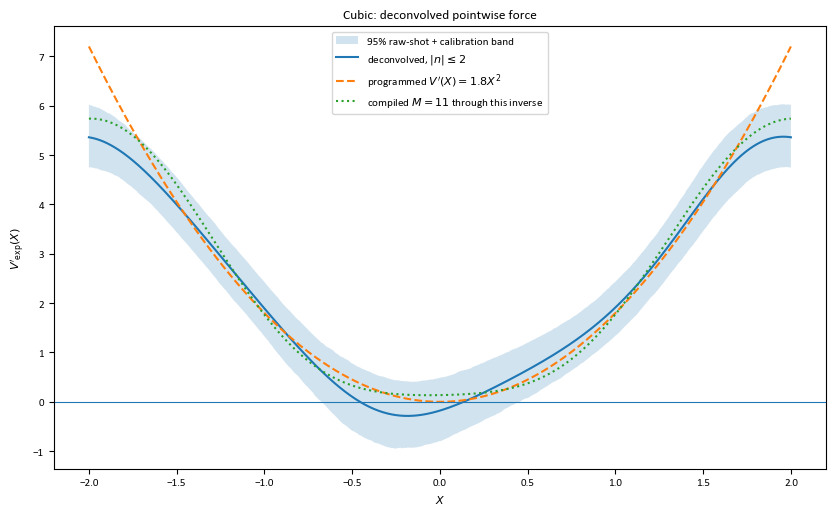

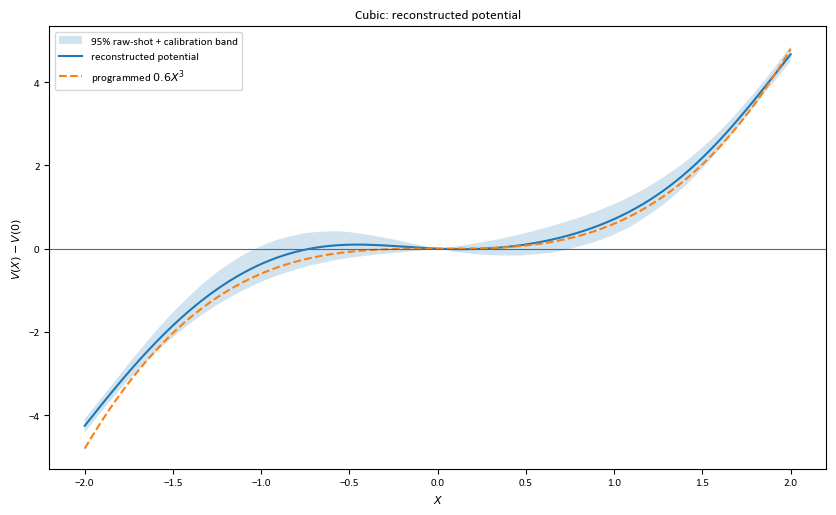

In [45]:
# The compiled curve overlaid here is Sim (F_COMP_EST, section 4.1): it has
# been through the same frozen inverse, and hence the same band limit, as the data.
boot_force = np.asarray(rec["force_boot"])
flo, fhi = np.nanpercentile(boot_force, [2.5, 97.5], axis=0)

xs   = XGRID[measured_support]
Vrec = integrate_force(xs, rec["force"][measured_support], zero_at=0.0)
Vb = np.array([integrate_force(xs, f[measured_support], 0.0)
               for f in boot_force if np.all(np.isfinite(f[measured_support]))])
vlo, vhi = np.nanpercentile(Vb, [2.5, 97.5], axis=0)
print(f"bootstrap draws usable for the potential: {len(Vb)} of {len(boot_force)}")

plt.figure(figsize=(8.4,5.2))
plt.fill_between(XGRID, flo, fhi, alpha=0.2, label="95% raw-shot + calibration band")
plt.plot(XGRID, rec["force"], label=fr"deconvolved, $|n|\leq{NMAX}$")
plt.plot(XGRID, 1.8*XGRID**2, "--", label=r"programmed $V'(X)=1.8X^2$")
plt.plot(XGRID, F_COMP_EST, ":", label=fr"compiled $M={QSP_ORDER_M}$ through this inverse")
plt.axhline(0, lw=0.8)
plt.xlabel(r"$X$"); plt.ylabel(r"$V'_{\rm exp}(X)$")
plt.title("Cubic: deconvolved pointwise force")
plt.legend(); plt.tight_layout()
plt.savefig(OUT/"13_deconvolved_force.png", dpi=300); plt.show()

Vtar_s = 0.6*xs**3; Vtar_s = Vtar_s - np.interp(0.0, xs, Vtar_s)
plt.figure(figsize=(8.4,5.2))
plt.fill_between(xs, vlo, vhi, alpha=0.2, label="95% raw-shot + calibration band")
plt.plot(xs, Vrec, label="reconstructed potential")
plt.plot(xs, Vtar_s, "--", label=r"programmed $0.6X^3$")
plt.axhline(0, lw=0.8)
plt.xlabel(r"$X$"); plt.ylabel(r"$V(X)-V(0)$")
plt.title("Cubic: reconstructed potential")
plt.legend(); plt.tight_layout()
plt.savefig(OUT/"14_reconstructed_potential.png", dpi=300); plt.show()

recon = pd.DataFrame({"X":XGRID, "a":rec["a"], "q":rec["q"],
                      "F_point":rec["force"], "F_lo95":flo, "F_hi95":fhi})
recon.to_csv(OUT/"15_reconstruction_curves.csv", index=False)

### 4.4 The Morse-gate rule applied to this probe
The Morse reconstruction (`05_morse`, section 4) spends the noise budget of hard truncation at
the gain cap on a smooth rolloff through $|n|\le8$: harmonic $n$ is returned with gain
$g_n=H_n/(H_n^2+\epsilon n^2)$, with $\epsilon$ fixed by $\sum_{n=1}^{8}g_n^2=\sum_{n\le n_{\max}}H_n^{-2}$.
The fraction of harmonic $n$ it keeps is $H_ng_n$. Applied to this coherent probe, the rule is
compared here with the hard cut at $|n|\le n_{\max}$ used for this gate (SM *Pointwise force
reconstruction*). Nothing downstream uses it.

In [46]:
# =====================================================================
#  CROSS-CHECK: the regularised rule of the Morse gate on this probe.
#  eps is fixed by the gain cap alone, as in 05_morse.ipynb:
#      sum_{n=1..8} g_n^2 = sum_{n<=n_max} 1/H_n^2,   g_n = H_n/(H_n^2 + eps n^2)
#  and harmonic n keeps the fraction H_n g_n = H_n^2/(H_n^2 + eps n^2).
#  Only printed and quoted; this gate is reconstructed by hard truncation.
# =====================================================================
from scipy.optimize import brentq as _mr_brentq

MORSE_RULE_NMAX, MORSE_RULE_P = 8, 2           # as in 05_morse.ipynb


def _mr_H(n):
    return float(np.exp(-0.5*SIGMA2*(2*np.pi*n/L)**2))


_mr_target = sum(_mr_H(n)**-2 for n in range(1, NMAX + 1))
_mr_power = lambda eps: sum((_mr_H(n)/(_mr_H(n)**2 + eps*n**MORSE_RULE_P))**2
                            for n in range(1, MORSE_RULE_NMAX + 1))
MORSE_RULE_EPS = 10**_mr_brentq(lambda le: _mr_power(10**le) - _mr_target, -14, 2)
MORSE_RULE_KEPT = {n: _mr_H(n)**2/(_mr_H(n)**2 + MORSE_RULE_EPS*n**MORSE_RULE_P)
                   for n in range(1, MORSE_RULE_NMAX + 1)}

print(f"probe sigma_X^2 = {SIGMA2:.4f};  hard cut at the gain cap: |n| <= {NMAX}")
print(f"Morse-gate rule: eps = {MORSE_RULE_EPS:.3e}")
print(f"{'n':>4}{'1/H_n':>11}{'fraction kept':>15}")
for _n, _f in MORSE_RULE_KEPT.items():
    print(f"{_n:4d}{1/_mr_H(_n):11.3g}{_f:15.4f}")

probe sigma_X^2 = 0.5476;  hard cut at the gain cap: |n| <= 2
Morse-gate rule: eps = 5.559e-05
   n      1/H_n  fraction kept
   1       1.97         0.9998
   2       14.9         0.9529
   3        437         0.0104
   4   4.95e+04         0.0000
   5   2.16e+07         0.0000
   6   3.65e+10         0.0000
   7   2.38e+14         0.0000
   8   5.99e+18         0.0000


## 5. Band-limited target
The programmed force truncated to the retained harmonics $|n|\le n_{\max}$; it uses no data and isolates the distortion of the band limit itself.

In [47]:
# =====================================================================
#  BAND-LIMITED TARGET: the programmed force truncated to the retained
#  harmonics |n| <= n_max on the Fourier interval [-L/2, L/2).  No data.
# =====================================================================
def band_limit(fn, nmax=None, L=L, nfft=8192):
    """Truncate fn to |n| <= nmax harmonics on the design interval."""
    nm = NMAX if nmax is None else int(nmax)
    xq = -L/2 + np.arange(nfft)/nfft*L
    yq = np.asarray(fn(xq), float)
    c  = {n: np.mean(yq*np.exp(-1j*2*np.pi*n/L*xq)) for n in range(nm+1)}
    def g(xx):
        xx = np.asarray(xx, float)
        out = np.full(xx.shape, c[0].real)
        for n in range(1, nm+1):
            k = 2*np.pi*n/L
            out = out + 2*(c[n].real*np.cos(k*xx) - c[n].imag*np.sin(k*xx))
        return out
    return g


F_BANDLIM = np.asarray(band_limit(dV_target)(XGRID), float)

## 6. Cubic gate
### 6.1 Analysis window
Largest $|X|\le W$ on a $0.2$ grid at which Sim plus the bootstrap fluctuations is consistent with a cubic, with median $p\ge$ `WINDOW_P_MIN` at $W$ and every smaller window (SM *Analysis windows*). Statistic: largest residual of the cubic fit in units of the pointwise bootstrap error; null distribution from the bootstrap draws with their cubic part removed. The same test on the data is reported alongside.

In [48]:
# =====================================================================
#  §6.1 --- ANALYSIS WINDOW from the reconstruction's consistency with a cubic
#
#  Test: least-squares cubic fit V' = c1 + 2 c2 X + 3 c3 X^2 to the
#  reconstructed force over |X| <= W.  Statistic: the largest residual in
#  units of the pointwise bootstrap sd, T = max_X |r(X)|/sd(X).  Its null
#  distribution comes from the bootstrap itself: each draw's fluctuation
#  about the reconstruction, with its own cubic part removed, gives one T.
#  Correlations between grid points are kept exactly; no covariance matrix
#  is inverted.
# =====================================================================
P_MIN = WINDOW_P_MIN                          # consistency threshold (section 1)
CUBIC_WINDOWS = np.round(np.arange(0.6, 2.0001, 0.2), 6)


def cubic_force_design(x):
    # Columns (c1, c2, c3) of V'(x) = c1 + 2 c2 x + 3 c3 x^2.
    x = np.asarray(x, float)
    return np.column_stack([np.ones_like(x), 2*x, 3*x**2])


_BF = np.asarray(boot_force)
_BF = _BF[np.all(np.isfinite(_BF[:, np.abs(XGRID) <= CUBIC_WINDOWS[-1] + 1e-9]), axis=1)]
_rows = []
for w_ in CUBIC_WINDOWS:
    m = np.abs(XGRID) <= w_ + 1e-9
    X_ = cubic_force_design(XGRID[m]); P_ = np.linalg.pinv(X_)
    resid = lambda y: y - X_@(P_@y)
    sd = _BF[:, m].std(axis=0, ddof=1)
    y_d = rec["force"][m]
    T_d = float(np.max(np.abs(resid(y_d))/sd))
    E = _BF[:, m] - _BF[:, m].mean(axis=0)             # bootstrap fluctuations
    T_b = np.max(np.abs(E - E@P_.T@X_.T)/sd, axis=1)   # null: cubic part removed
    # a perfect device at this noise level: compiled-through-inverse curve plus
    # each bootstrap fluctuation; its typical (median) p-value
    y_c = F_COMP_EST[m]
    T_null = np.sort(T_b)
    T_pd = np.max(np.abs((y_c + E) - (y_c + E)@P_.T@X_.T)/sd, axis=1)
    p_pd = 1.0 - np.searchsorted(T_null, T_pd, side="left")/len(T_null)
    c3_b = (_BF[:, m]@P_.T)[:, 2]
    _rows.append({"window": w_, "c3": float((P_@y_d)[2]), "c3_se": float(c3_b.std(ddof=1)),
                  "T": T_d, "p": float(np.mean(T_b >= T_d)),
                  "compiled via inverse: c3": float((P_@y_c)[2]),
                  "compiled via inverse: median p": float(np.median(p_pd))})
cubic_window_tbl = pd.DataFrame(_rows)
display(cubic_window_tbl.round(4))
cubic_window_tbl.to_csv(OUT/"15b_cubic_window_scan.csv", index=False)

def _nested_window(pcol):
    ok = (cubic_window_tbl[pcol] >= P_MIN).to_numpy()
    n_ok = int(np.argmin(ok)) if not ok.all() else len(ok)   # nested: stop at first failure
    return (float(CUBIC_WINDOWS[n_ok - 1]) if n_ok else np.nan), n_ok


W_DATA, _ = _nested_window("p")
W_REF, _ = _nested_window("compiled via inverse: median p")
print(f"largest window with p >= {P_MIN} at it and every smaller window:")
print(f"  data                                 |X| <= {W_DATA}")
print(f"  perfect device at this noise level   |X| <= {W_REF}"
      "   (compiled through the same inverse, median p)")

# The window is set by Sim at the measured noise (it uses the data's noise,
# not its values); the data's own window is printed for information only.
W_ANALYSIS = W_REF
if not np.isfinite(W_ANALYSIS):
    raise ValueError("no window passes the Sim criterion")
_r = cubic_window_tbl.set_index("window").loc[W_ANALYSIS]
CUBIC_C3, CUBIC_C3_SE = float(_r.c3), float(_r.c3_se)
print(f"\nW_ANALYSIS = {W_ANALYSIS}")
print(f"  cubic fit: c3 = {CUBIC_C3:.3f} +/- {CUBIC_C3_SE:.3f};  compiled through the "
      f"same inverse {_r['compiled via inverse: c3']:.3f};  programmed {C3_TARGET}")
print(f"  data consistency with a cubic at this window: p = {_r.p:.3g}")
print("  W_ANALYSIS is used by the coefficients, the acceptance table and the figures.")

,window,c3,c3_se,T,p,compiled via inverse: c3,compiled via inverse: median p
0,0.6,0.7367,0.4054,0.4840,0.3355,0.3185,0.4260
1,0.8,0.7246,0.3145,0.8053,0.4740,0.4190,0.3968
2,1.0,0.7038,0.2282,0.9643,0.6275,0.5161,0.3882
3,1.2,0.6808,0.1526,0.8691,0.7755,0.5936,0.4088
4,1.4,0.6574,0.0900,0.8305,0.8030,0.6393,0.4745
5,1.6,0.6288,0.0421,0.8831,0.7505,0.6479,0.3510
6,1.8,0.5875,0.0134,1.8482,0.2550,0.6202,0.1295
7,2.0,0.5280,0.0167,3.7454,0.0050,0.5623,0.0025


largest window with p >= 0.1 at it and every smaller window:
  data                                 |X| <= 1.8
  perfect device at this noise level   |X| <= 1.8   (compiled through the same inverse, median p)

W_ANALYSIS = 1.8
  cubic fit: c3 = 0.587 +/- 0.013;  compiled through the same inverse 0.620;  programmed 0.6
  data consistency with a cubic at this window: p = 0.255
  W_ANALYSIS is used by the coefficients, the acceptance table and the figures.


### 6.2 Coefficients along the ladder
Quartic fit $\sum_{n=1}^4 n v_nX^{n-1}$ (columns `c1..c4` are $v_1..v_4$) to the programmed force, the compiled force, Sim and the experiment.

In [49]:
# =====================================================================
#  §6.2 --- COEFFICIENT LADDER.
#      programmed target -> compiled exact -> compiled through the estimator
#      -> experiment
#
#  The cubic has no topology to track: its force is a parabola with no sign
#  change, so the ladder is the quartic decomposition alone.  Each adjacent
#  pair isolates one effect: truncation, then the band limit, then the device.
#
#  Defines LADDER_CURVES, reused by §6.3.
# =====================================================================
LADDER_CURVES = (
    ("programmed target",          np.asarray(dV_target(XGRID), float)),
    ("compiled exact",             np.asarray(FPOINT_COMP, float)),
    ("compiled through estimator", np.asarray(F_COMP_EST, float)),
    ("experiment",                 np.asarray(rec["force"], float)),
)

def quartic_from_force(curve, lim=None):
    """Fit V = sum_n c_n X^n to a force curve over |X| <= lim."""
    w = np.abs(XGRID) <= (W_ANALYSIS if lim is None else lim)
    A = np.column_stack([n*XGRID[w]**(n-1) for n in (1, 2, 3, 4)])
    y = np.asarray(curve, float)[w]; ok = np.isfinite(y)
    return np.linalg.lstsq(A[ok], y[ok], rcond=None)[0]


_rows=[]
for _name,_curve in LADDER_CURVES:
    _c=quartic_from_force(_curve)
    _rows.append({"curve":_name,**{f"c{j+1}":_c[j] for j in range(4)}})
cubic_coeff_ladder=pd.DataFrame(_rows)
display(cubic_coeff_ladder.round(4))
cubic_coeff_ladder.to_csv(OUT/"22c_cubic_coefficient_ladder.csv",index=False)

print(f"\nRead the c3 column downwards: programmed {C3_TARGET} -> what an M={QSP_ORDER_M}")
print(f"compilation can deliver -> what the n_max={NMAX} inverse returns from that")
print("-> what the experiment returns.  Only the last step is the device.")
_c3=cubic_coeff_ladder.set_index("curve").c3
print(f"\n  truncation  {_c3['programmed target']:.4f} -> {_c3['compiled exact']:.4f}"
      f"   ({100*(_c3['compiled exact']/_c3['programmed target']-1):+.1f}%)")
print(f"  band limit  {_c3['compiled exact']:.4f} -> {_c3['compiled through estimator']:.4f}"
      f"   ({100*(_c3['compiled through estimator']/_c3['compiled exact']-1):+.1f}%)")
print(f"  device      {_c3['compiled through estimator']:.4f} -> {_c3['experiment']:.4f}"
      f"   ({100*(_c3['experiment']/_c3['compiled through estimator']-1):+.1f}%)")
print("  the first two systematics act in opposite directions and partly cancel.")

,curve,c1,c2,c3,c4
0,programmed target,0.0000,-0.0000,0.6000,0.0000
1,compiled exact,-0.0337,-0.0017,0.6258,0.0005
2,compiled through estimator,-0.0219,0.0107,0.6204,-0.0040
3,experiment,-0.0129,0.0899,0.5877,-0.0149



Read the c3 column downwards: programmed 0.6 -> what an M=11
compilation can deliver -> what the n_max=2 inverse returns from that
-> what the experiment returns.  Only the last step is the device.

  truncation  0.6000 -> 0.6258   (+4.3%)
  band limit  0.6258 -> 0.6204   (-0.9%)
  device      0.6204 -> 0.5877   (-5.3%)
  the first two systematics act in opposite directions and partly cancel.


### 6.3 Coefficients at the analysis window
$v_1,\dots,v_4$ of the experiment with their bootstrap standard deviations and 95% intervals, against the programmed, compiled and Sim values (SM *Cubic gate: coefficients*).

In [50]:
# =====================================================================
#  §6.3 --- CUBIC COEFFICIENTS at the analysis window.
#
#  c_n = v_n with raw-shot bootstrap intervals, read against Sim (the
#  compiled circuit through the same estimator) rather than against the
#  programmed values: only Sim has been through the same truncation and
#  band limit as the data.
# =====================================================================
_nom = quartic_from_force(rec["force"])
_bt  = np.array([quartic_from_force(f) for f in boot_force
                 if np.all(np.isfinite(f[np.abs(XGRID) <= W_ANALYSIS]))])
_lo, _hi = np.percentile(_bt, [2.5, 97.5], axis=0)
_sd = _bt.std(axis=0, ddof=1)

_L = cubic_coeff_ladder.set_index("curve")
claims_cubic = pd.DataFrame({
    "coefficient": [f"c{j+1}" for j in range(4)],
    "programmed":  [_L.loc["programmed target", f"c{j+1}"] for j in range(4)],
    "compiled_exact": [_L.loc["compiled exact", f"c{j+1}"] for j in range(4)],
    "compiled_via_estimator": [_L.loc["compiled through estimator", f"c{j+1}"] for j in range(4)],
    "experiment": _nom, "sigma": _sd, "lo95": _lo, "hi95": _hi,
})
claims_cubic["z_vs_via_estimator"] = (
    (claims_cubic.experiment - claims_cubic.compiled_via_estimator)/claims_cubic.sigma)
claims_cubic["z_vs_programmed"] = (
    (claims_cubic.experiment - claims_cubic.programmed)/claims_cubic.sigma)
display(claims_cubic.round(4))
claims_cubic.to_csv(OUT/"30_cubic_claims.csv", index=False)

_r = claims_cubic[claims_cubic.coefficient == "c3"].iloc[0]
print(f"\ncubic coefficient over |X| <= {W_ANALYSIS:.3f}, "
      f"{len(_bt)} bootstrap replicas")
print(f"   experiment              c3 = {_r.experiment:.3f} +/- {_r['sigma']:.3f}"
      f"   95% [{_r.lo95:.3f}, {_r.hi95:.3f}]")
print(f"   compiled via estimator  c3 = {_r.compiled_via_estimator:.3f}"
      f"   -> z = {_r.z_vs_via_estimator:+.2f}")
print(f"   programmed              c3 = {_r.programmed:.3f}"
      f"   -> z = {_r.z_vs_programmed:+.2f}")
print("   The first z is the hardware statement.  The second charges the device")
print("   for the truncation and the band limit as well, and is not the claim.")

,coefficient,programmed,compiled_exact,compiled_via_estimator,experiment,sigma,lo95,hi95,z_vs_via_estimator,z_vs_programmed
0,c1,0.0,-0.0337,-0.0219,-0.0129,0.0401,-0.0925,0.0646,0.2249,-0.3220
1,c2,-0.0,-0.0017,0.0107,0.0899,0.1245,-0.1598,0.3344,0.6364,0.7222
2,c3,0.6,0.6258,0.6204,0.5877,0.0135,0.5613,0.6143,-2.4329,-0.9129
3,c4,0.0,0.0005,-0.0040,-0.0149,0.0420,-0.0960,0.0698,-0.2583,-0.3537



cubic coefficient over |X| <= 1.800, 2000 bootstrap replicas
   experiment              c3 = 0.588 +/- 0.013   95% [0.561, 0.614]
   compiled via estimator  c3 = 0.620   -> z = -2.43
   programmed              c3 = 0.600   -> z = -0.91
   The first z is the hardware statement.  The second charges the device
   for the truncation and the band limit as well, and is not the claim.


## 7. Acceptance and post-selection
Compiled acceptance $A_M^2$, its probe average, and the measured $p_g$ over the analysis window (SM *Acceptance and post-selection*).

In [51]:
# =====================================================================
#  ACCEPTANCE AND POST-SELECTION over the analysis window
#    A_M^2         compiled acceptance |K_g(X)|^2, pointwise over the window
#    <A_M^2>_mu    compiled acceptance averaged over the probe, at the probe
#                  centres in the window
#    p_g           measured post-selection probability at the same centres
# =====================================================================
ACC_WINDOW = float(W_ANALYSIS)
_xg = np.linspace(-ACC_WINDOW, ACC_WINDOW, 2001)
_mu = data.mu.to_numpy(float)
_sel = np.abs(_mu) <= ACC_WINDOW + 1e-9
ACCEPTANCE = {"A_M^2 pointwise": series(CA, _xg),
              "<A_M^2>_mu": compiled_coherent(_mu[_sel])[1],
              "p_g measured": data.pg.to_numpy(float)[_sel]}
acc_tbl = pd.DataFrame([{"quantity": k, "mean": np.mean(v), "min": np.min(v),
                         "max": np.max(v), "n": len(v)} for k, v in ACCEPTANCE.items()])
print(f"acceptance over |X| <= {ACC_WINDOW:g}:")
display(acc_tbl.round(4))
acc_tbl.to_csv(OUT / "acceptance_window.csv", index=False)

acceptance over |X| <= 1.8:


,quantity,mean,min,max,n
0,A_M^2 pointwise,0.9734,0.9306,1.0000,2001
1,<A_M^2>_mu,0.9750,0.9698,0.9820,19
2,p_g measured,0.8553,0.8459,0.8679,19


## 8. Agreement with Sim on the measured points
The probe-averaged forces against the probe response of the compiled circuit, with the
raw-shot bootstrap covariance of the forces, over the analysis window(s) and over all
probes. No reconstruction and no target enter (SM *Agreement with Sim*).

In [52]:
# =====================================================================
#  §8 --- AGREEMENT WITH SIM ON THE MEASURED POINTS.  chi2 = d^T C^-1 d,
#  d the measured minus the compiled probe-averaged force at each probe,
#  C the raw-shot bootstrap covariance of the measured forces.
# =====================================================================
_mu_p = data.mu.to_numpy(float)
_F_p = data.force.to_numpy(float)
_C_p = np.cov(np.asarray(Fb, float), rowvar=False, ddof=1)
_F_c = np.asarray(compiled_coherent(_mu_p)[0], float)

_wins = {f"analysis window |X| <= {float(W_ANALYSIS):g}": float(W_ANALYSIS),
         "full range |X| <= 2": L/2 + 1e-6}

def _chi2_points(sel):
    """chi2 = d^T C^-1 d on the resolved eigenmodes of C, and the pulls."""
    d = (_F_p - _F_c)[sel]
    C = _C_p[np.ix_(sel, sel)]; C = (C + C.T)/2
    ev, U = np.linalg.eigh(C)
    keep = ev > max(float(ev.max())*1e-10, 1e-18)
    z = (U[:, keep].T @ d)/np.sqrt(ev[keep])
    chi = float(z @ z); k = int(keep.sum())
    pull = d/np.sqrt(np.clip(np.diag(C), 1e-300, None))
    return {"n": int(sel.sum()), "chi2": chi, "dof": k, "p": float(chi2_dist.sf(chi, k)),
            "rms_pull": float(np.sqrt(np.mean(pull**2))), "max_abs_pull": float(np.max(np.abs(pull)))}


_rows = []
for _name, _W in _wins.items():
    _r = _chi2_points(np.abs(_mu_p) <= _W + 1e-9)
    _rows.append({"range": _name, **_r})
    PAPER[f"sim_points.{_name.split(' |')[0].replace(' ', '_')}.W_n_chi2_dof_p_rmspull"] = [
        _W if _W < 1.99 else 2.0, _r["n"], _r["chi2"], _r["dof"], _r["p"], _r["rms_pull"]]
SIM_POINTS = pd.DataFrame(_rows)
print("measured probe-averaged forces against the compiled response (raw-shot covariance):")
display(SIM_POINTS.round(4))

measured probe-averaged forces against the compiled response (raw-shot covariance):


,range,n,chi2,dof,p,rms_pull,max_abs_pull
0,analysis window |X| <= 1.8,19,51.3344,19,0.0001,2.3140,4.653
1,full range |X| <= 2,21,52.0512,21,0.0002,2.3782,4.653


## 9. Values quoted in the paper

In [53]:
# =====================================================================
#  VALUES QUOTED IN THE PAPER -- cubic gate
# =====================================================================
P = PAPER
P["acq.probe"] = "coherent"
P["acq.scans"] = 1
P["acq.probe_centres"] = len(records)
P["acq.reps_per_cf_point"] = sorted({int(r["N"]) for r in records})
P["acq.cf_points_per_cut"] = sorted({int(r["ncf"]) for r in records})
P["acq.binary_outcomes"] = int(sum(int(r["N"])*int(r["ncf"]) for r in records))
P["acq.vacuum_calibrations"] = len(cross)
P["cal.Lambda"] = [float(c["primary"]["den"]) for c in cross]
P["cal.Lambda_se"] = [float(c["primary"]["se"]) for c in cross]
P["cal.cf_fit_degree"] = int(CF_ORDER)
P["cal.crosshair_sigma_X2"] = [float(v) for v in SIGMA2_MEASURED]
# ---- probe and bandwidth -----------------------------------------------
P["probe.sigma_X2"] = float(SIGMA2)
P["bandwidth.n_max"] = int(NMAX)
P["bandwidth.inverse_gain_n1..nmax+1"] = [float(np.exp(0.5*SIGMA2*(2*np.pi*n/L)**2))
                                          for n in range(1, NMAX + 2)]
# ---- compiled circuit ----------------------------------------------------
P["circuit.M"] = int(QSP_ORDER_M)
# ---- reconstruction --------------------------------------------------------
P["recon.w_channel.chi2_dof_p"] = [rec["fit_a"]["chi2"], rec["fit_a"]["dof"], rec["fit_a"]["p"]]
P["recon.q_channel.chi2_dof_p"] = [rec["fit_q"]["chi2"], rec["fit_q"]["dof"], rec["fit_q"]["p"]]
P["recon.min_w_on_probed_range"] = float(np.min(rec["a"][measured_support]))
P["recon.bootstrap_replicas"] = int(np.asarray(rec["force_boot"]).shape[0])
# ---- acceptance --------------------------------------------------------------
P["acceptance.window"] = ACC_WINDOW
for _k, _v in ACCEPTANCE.items():
    P[f"acceptance.{_k}.mean_min_max"] = [float(np.mean(_v)), float(np.min(_v)), float(np.max(_v))]

# ---- SM "Cubic gate: bandwidth": the n_max test and the content of 1.8 X^2 above |n| = 2
P["cubic.stress.nmax"] = stress.nmax.tolist()
P["cubic.stress.inverse_gain"] = stress.inverse_gain.tolist()
P["cubic.stress.min_w"] = stress.min_a.tolist()
P["cubic.stress.q_channel_p"] = stress.Q_p.tolist()
_xp = -L/2 + np.arange(8192)/8192*L
_fp = np.asarray(dV_target(_xp), float)
_pw = np.abs(np.fft.rfft(_fp)/len(_fp))[1:]**2
P["cubic.programmed_force.power_above_n2"] = float(_pw[2:].sum()/_pw.sum())
_ft = band_limit(dV_target, nmax=2)(_xp)
P["cubic.programmed_force.trunc_n2_rms_rel"] = float(np.sqrt(np.mean((_fp-_ft)**2))
                                                     / np.sqrt(np.mean(_fp**2)))
# ---- analysis window -------------------------------------------------------
P["window.threshold"] = WINDOW_P_MIN
P["window.W"] = float(W_ANALYSIS)
P["window.scan.W"] = cubic_window_tbl["window"].tolist()
P["window.scan.Sim_median_p"] = cubic_window_tbl["compiled via inverse: median p"].tolist()
P["window.scan.data_p"] = cubic_window_tbl["p"].tolist()
P["window.scan.v3"] = cubic_window_tbl["c3"].tolist()
P["window.scan.v3_se"] = cubic_window_tbl["c3_se"].tolist()
P["window.scan.v3_Sim"] = cubic_window_tbl["compiled via inverse: c3"].tolist()
# ---- coefficients at the analysis window ------------------------------------
_bl = quartic_from_force(F_BANDLIM)
for _j in range(4):
    _r = claims_cubic.iloc[_j]
    P[f"cubic.v{_j+1}.prog_bandlim_comp_Sim_exp_sd_lo95_hi95"] = [
        _r.programmed, _bl[_j], _r.compiled_exact, _r.compiled_via_estimator,
        _r.experiment, _r.sigma, _r.lo95, _r.hi95]
# ---- the Morse-gate rule applied to this probe (section 4) ----------------------
P["crosscheck.morse_rule.eps"] = float(MORSE_RULE_EPS)
P["crosscheck.morse_rule.kept_fraction_n1..8"] = [float(MORSE_RULE_KEPT[n])
                                                   for n in range(1, MORSE_RULE_NMAX + 1)]
# ---- cubic coefficient against Sim and the programmed value, in standard deviations --
_v3 = P["cubic.v3.prog_bandlim_comp_Sim_exp_sd_lo95_hi95"]
P["cubic.v3.z_vs_Sim_vs_programmed"] = [(_v3[4] - _v3[3])/_v3[5], (_v3[4] - _v3[0])/_v3[5]]
P["cubic.v3.rel_to_programmed"] = (_v3[4] - _v3[0])/_v3[0]

In [54]:
# =====================================================================
#  Print the collected values between fixed markers (read by
#  extract_outputs.py) and write them to OUT/paper_values.json.
# =====================================================================
def _plain(v):
    if isinstance(v, dict):
        return {str(k): _plain(x) for k, x in v.items()}
    if isinstance(v, (list, tuple, np.ndarray)):
        return [_plain(x) for x in list(np.asarray(v, dtype=object).ravel())] \
            if isinstance(v, np.ndarray) else [_plain(x) for x in v]
    if isinstance(v, (np.bool_, bool)):
        return bool(v)
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.floating, float)):
        return float(v)
    return v


def _fmt(v):
    v = _plain(v)
    if isinstance(v, bool):
        return str(v)
    if isinstance(v, int):
        return str(v)
    if isinstance(v, float):
        if not np.isfinite(v):
            return "nan"
        return f"{v:.4g}" if (v == 0 or 1e-3 <= abs(v) < 1e5) else f"{v:.3e}"
    if isinstance(v, list):
        return "[" + ", ".join(_fmt(x) for x in v) + "]"
    if isinstance(v, dict):
        return "{" + ", ".join(f"{k}: {_fmt(x)}" for k, x in v.items()) + "}"
    return str(v)


import json
print(f"===== PAPER VALUES: {GATE} =====")
for _k, _v in PAPER.items():
    print(f"{_k} = {_fmt(_v)}")
print(f"===== END PAPER VALUES: {GATE} =====")
(OUT / "paper_values.json").write_text(json.dumps(_plain(PAPER), indent=1, default=str))

===== PAPER VALUES: cubic =====
recon.input_probe_centres = 21
sim_points.analysis_window.W_n_chi2_dof_p_rmspull = [1.8, 19, 51.33, 19, 8.317e-05, 2.314]
sim_points.full_range.W_n_chi2_dof_p_rmspull = [2, 21, 52.05, 21, 1.878e-04, 2.378]
acq.probe = coherent
acq.scans = 1
acq.probe_centres = 21
acq.reps_per_cf_point = [10000]
acq.cf_points_per_cut = [21]
acq.binary_outcomes = 4410000
acq.vacuum_calibrations = 1
cal.Lambda = [1.925]
cal.Lambda_se = [0.02454]
cal.cf_fit_degree = 5
cal.crosshair_sigma_X2 = [0.5476]
probe.sigma_X2 = 0.5476
bandwidth.n_max = 2
bandwidth.inverse_gain_n1..nmax+1 = [1.965, 14.91, 437.1]
circuit.M = 11
recon.w_channel.chi2_dof_p = [600.2, 15, 3.197e-118]
recon.q_channel.chi2_dof_p = [21.05, 16, 0.1767]
recon.min_w_on_probed_range = 0.8846
recon.bootstrap_replicas = 2000
acceptance.window = 1.8
acceptance.A_M^2 pointwise.mean_min_max = [0.9734, 0.9306, 1]
acceptance.<A_M^2>_mu.mean_min_max = [0.975, 0.9698, 0.982]
acceptance.p_g measured.mean_min_max = [0.8553, 

4375

## 10. Figures
Main-text Fig. 2(a,b): force and potential panels. `SAVE_FOR_EXPORT = True` writes bare SVG panels (no text) for assembly.

bootstrap draws usable for the potential: 2000 of 2000
compiled curve plotted: compiled through $|n|\leq2$ inverse   (COMPILED_THROUGH_ESTIMATOR = True)


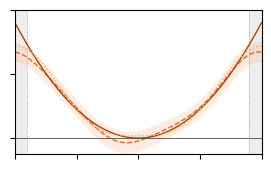

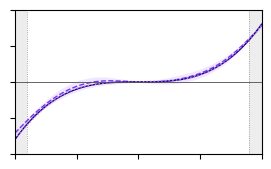

In [55]:
# =====================================================================
#  §10 --- Styled cubic force and potential panels for export.
#  Same figure pair as the other gates; the compiled curve is the one that
#  has been through the frozen inverse (see the flag below).
#
#  COMPILED_THROUGH_ESTIMATOR selects which compiled curve is drawn:
#    True   the compiled circuit after the frozen n_max inverse (F_COMP_EST,
#           from section 4.1).  Like-for-like against the data, since both have been
#           through the same band limit.  This is the default.
#    False  the exact compiled pointwise force (FPOINT_COMP) and, for the
#           potential, the compiled phase profile VPHASE_COMP.  The ceiling
#           the inverse is trying to reach, not a fair comparison to the data.
#
#  Note the two branches do not plot the same KIND of object in the potential
#  figure: True integrates the band-limited force, False shows -arg(K_g).
#  They differ by the band limit, which is the point of the switch.
#
# =====================================================================
from matplotlib.ticker import MultipleLocator

SAVE_FOR_EXPORT = True   # True: no title/axis labels/tick numbers, small figsize
                         # False: title + axis labels, bigger preview figsize

CM = 1 / 2.54
FIGSIZE_EXPORT  = (7 * CM,4.4 * CM)
FIGSIZE_PREVIEW = (8.4, 5.2)
FIGSIZE = FIGSIZE_EXPORT if SAVE_FOR_EXPORT else FIGSIZE_PREVIEW

LW = 1.0
MARKER_EVERY = None
MARKER       = "o"
MARKER_SIZE  = 2.5

# --- force plot: all orange, three shades -------------------------------
FORCE_COLOR_TARGET   = "#AE4500"   # dark orange  — programmed target
FORCE_COLOR_RECON    = "#FB6023"   # mid orange   — deconvolved experiment
FORCE_COLOR_COMPILED = "#FFA366"   # light orange — compiled accepted branch

# --- potential plot: all purple, matching shades/linestyles -------------
POT_COLOR_TARGET   = "#2A0080"
POT_COLOR_RECON    = "#7534F8"
POT_COLOR_COMPILED = "#AE88F9"

LS_RECON, LS_TARGET, LS_COMPILED = "--", "-", ":"
COLOR_BOUNDARY = "0.55"

# --- axis limits / ticks, per plot --------------------------------------
XLIM = (-2.0, 2.0)
YLIM_FORCE     = (-1.0, 8.0)
YLIM_POTENTIAL = (-6.0, 6.0)
XTICK_STEP_FORCE     = 1.0
YTICK_STEP_FORCE     = 4.0
XTICK_STEP_POTENTIAL = 1.0
YTICK_STEP_POTENTIAL = 3.0

# Which compiled curve to draw; see the header.  True is the like-for-like
# comparison against the data and is what the paper figures use.
COMPILED_THROUGH_ESTIMATOR = True

DESIGN_HALF_WIDTH = 2.0
BOUNDARY_INNER = W_ANALYSIS

plt.rcParams.update({
    "font.size": 8,
    "font.family": "sans-serif",
    "font.sans-serif": ["Calibri"],
    "figure.facecolor": "none",
    "axes.facecolor": "none",
    "savefig.transparent": True,
    "svg.fonttype": "none",
})

marker_kwargs = dict(marker=MARKER, markevery=MARKER_EVERY, markersize=MARKER_SIZE) \
                if MARKER_EVERY else {}


def add_design_range_shading(ax):
    for sign in (+1, -1):
        lo, hi = sorted((sign * BOUNDARY_INNER, sign * DESIGN_HALF_WIDTH))
        ax.axvspan(lo, hi, color=COLOR_BOUNDARY, alpha=0.15, lw=0, zorder=0)
        ax.axvline(sign * BOUNDARY_INNER, color=COLOR_BOUNDARY,
                   linestyle=":", linewidth=0.6, zorder=1)


def style_axes(ax, title, xlabel, ylabel):
    if not SAVE_FOR_EXPORT:
        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
    else:
        ax.tick_params(labelbottom=False, labelleft=False)


def apply_axis_limits(ax, ylim=None, xtick=None, ytick=None):
    ax.set_xlim(XLIM)
    if ylim is not None and ylim != (None, None):
        ax.set_ylim(ylim)
    if xtick is not None:
        ax.xaxis.set_major_locator(MultipleLocator(xtick))
    if ytick is not None:
        ax.yaxis.set_major_locator(MultipleLocator(ytick))


# ============================================================
#  Data prep.  Potentials are referenced to the origin.
# ============================================================
xs = XGRID[measured_support]
vref = 0.0                      # the cubic has no barrier; use the origin

Vrec = integrate_force(xs, rec["force"][measured_support], zero_at=vref)
vb = np.array([integrate_force(xs, f[measured_support], vref)
               for f in boot_force if np.all(np.isfinite(f[measured_support]))])
vlo, vhi = np.nanpercentile(vb, [2.5, 97.5], axis=0)
print(f"bootstrap draws usable for the potential: {len(vb)} of {len(boot_force)}")

Vtar_s = V_target(xs) - V_target(vref)

if COMPILED_THROUGH_ESTIMATOR:
    # F_COMP_EST is built on XGRID (section 4.1), so it is not resampled.
    assert np.shape(F_COMP_EST) == np.shape(XGRID), "F_COMP_EST must be on XGRID"
    Fcomp = np.asarray(F_COMP_EST, float)
    Vcomp = integrate_masked(Fcomp, measured_support, zero_at=vref)[measured_support]
    _comp_label = fr"compiled through $|n|\leq{NMAX}$ inverse"
else:
    Fcomp = np.interp(XGRID, XCOMP, FPOINT_COMP)
    Vcomp = np.interp(xs, XCOMP, VPHASE_COMP)
    Vcomp = Vcomp - np.interp(vref, xs, Vcomp)
    _comp_label = "compiled accepted branch"

print(f"compiled curve plotted: {_comp_label}"
      f"   (COMPILED_THROUGH_ESTIMATOR = {COMPILED_THROUGH_ESTIMATOR})")


# ============================================================
#  Figure 1: pointwise force  (all orange)
# ============================================================
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.fill_between(XGRID, flo, fhi, color=FORCE_COLOR_COMPILED, alpha=0.2, lw=0,
                label="95% raw-shot + calibration band")
ax.plot(XGRID, rec["force"], LS_RECON, color=FORCE_COLOR_RECON, lw=LW,
        label=fr"deconvolved, $|n|\leq{NMAX}$", **marker_kwargs)
ax.plot(XGRID, dV_target(XGRID), LS_TARGET, color=FORCE_COLOR_TARGET, lw=LW,
        label=r"programmed $V'(X)=1.8X^2$")
ax.plot(XGRID, Fcomp, LS_COMPILED, color=FORCE_COLOR_COMPILED, lw=LW, label=_comp_label)
ax.axhline(0, lw=0.6, color="0.3")
add_design_range_shading(ax)
apply_axis_limits(ax, ylim=YLIM_FORCE, xtick=XTICK_STEP_FORCE, ytick=YTICK_STEP_FORCE)
style_axes(ax, "Cubic: deconvolved pointwise force", r"$X$", r"$V'_{\rm exp}(X)$")
if not SAVE_FOR_EXPORT:
    ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "12_force_vs_target.svg", format="svg", transparent=True)
plt.show()


# ============================================================
#  Figure 2: potential  (all purple, matching linestyles)
# ============================================================
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.fill_between(xs, vlo, vhi, color=POT_COLOR_COMPILED, alpha=0.2, lw=0,
                label="95% raw-shot + calibration band")
ax.plot(xs, Vrec, LS_RECON, color=POT_COLOR_RECON, lw=LW,
        label="reconstructed potential", **marker_kwargs)
ax.plot(xs, Vtar_s, LS_TARGET, color=POT_COLOR_TARGET, lw=LW,
        label=r"programmed $0.6X^3$")
ax.plot(xs, Vcomp, LS_COMPILED, color=POT_COLOR_COMPILED, lw=LW, label=_comp_label)
ax.axhline(0, lw=0.6, color="0.3")
add_design_range_shading(ax)
apply_axis_limits(ax, ylim=YLIM_POTENTIAL, xtick=XTICK_STEP_POTENTIAL, ytick=YTICK_STEP_POTENTIAL)
style_axes(ax, "Cubic: reconstructed potential", r"$X$", r"$V(X)-V(X_{\rm ref})$")
if not SAVE_FOR_EXPORT:
    ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "13_potential_vs_target.svg", format="svg", transparent=True)
plt.show()


# ============================================================
#  CSV export
# ============================================================
pd.DataFrame({
    "X": XGRID, "a": rec["a"], "q": rec["q"],
    "F_point": rec["force"], "F_lo95": flo, "F_hi95": fhi,
    "F_programmed": dV_target(XGRID),
    "F_compiled_plotted": Fcomp,
    "F_compiled_through_estimator": np.asarray(F_COMP_EST, float),
    "F_compiled_exact": np.interp(XGRID, XCOMP, FPOINT_COMP),
    "A_compiled": np.interp(XGRID, XCOMP, AMPL_COMP),
}).to_csv(OUT / "23_reconstruction_curves.csv", index=False)